# Task 4: Game Title Detection (5 เกม · Macro F1)

ภาพ screenshot ขนาด 230×120 ที่ถูกทำให้เสีย (หมุน, สีเพี้ยน, กลับสี, noise) → ทายว่ามาจากเกมไหน · 0 = 7-11k, 1 = fiveN, 2 = freefried, 3 = pube, 4 = roblock (ตาม datacard)

| ส่วน | ทำอะไร |
|---|---|
| 1–3 | setup, โหลดภาพเข้า RAM, EDA |
| 4–5 | ที่เก็บผลใน Drive + เครื่องมือ train บน GPU |
| 6–7 | สร้าง validation ที่ไม่มีภาพเกือบซ้ำกับ train (group split) และแสดงว่า val แบบสุ่มหลอกเรา |
| 8–9 | เทียบ 7 model (CNN 4 + ViT 3) บน group split → เลือก ensemble |
| 10 | train ชุดที่เลือกบน train ทั้งหมด → ทำนาย test → `task4_pred.csv` |

**รันใหม่หลัง runtime หลุด:** Run all ได้เลย ทุก model ที่ train เสร็จแล้วถูกเก็บใน `MyDrive/ml_task4_runs_v3/` และจะถูกโหลดแทนการ train ซ้ำ

## 1. Setup

In [ ]:
# ===== 1. Setup: mount Drive → แตก zip ข้อมูล → เช็ก GPU =====
import os, glob, time, json, math, gc, shutil, subprocess, itertools
from google.colab import drive
drive.mount('/content/drive')
ZIP = '/content/drive/MyDrive/ml_task4_data.zip'
RUN_DIR = '/content/drive/MyDrive/ml_task4_runs_v3'; os.makedirs(RUN_DIR, exist_ok=True)
t0 = time.time()
if not os.path.exists('/content/data/.done'):
    shutil.copy(ZIP, '/content/data.zip')
    subprocess.run(['unzip', '-q', '-o', '/content/data.zip', '-d', '/content/data'], check=True)
    open('/content/data/.done', 'w').close()
DATA_DIR = os.path.dirname(glob.glob('/content/data/**/train.csv', recursive=True)[0])

import numpy as np, pandas as pd, torch, timm, matplotlib.pyplot as plt
DEV = 'cuda'
print(f'zip {os.path.getsize(ZIP)/1e6:.0f} MB → {DATA_DIR} | train/ {len(os.listdir(DATA_DIR + "/train")):,} | test/ {len(os.listdir(DATA_DIR + "/test")):,} | {time.time()-t0:.0f}s')
print(f'torch {torch.__version__} | timm {timm.__version__} | {torch.cuda.get_device_name()} {torch.cuda.get_device_properties(0).total_memory/1e9:.0f} GB | CPU {os.cpu_count()}')

Mounted at /content/drive
zip 606 MB → /content/data | train/ 31,546 | test/ 25,889 | 32s
torch 2.14.1+cu130 | timm 1.0.31 | NVIDIA A100-SXM4-40GB 42 GB | CPU 12


**ผล:** แตก zip 606 MB ได้ภาพ train 31,546 / test 25,889 ภาพ ใน ≈30 วินาที · GPU = A100 40 GB
- **ทำอะไร:** mount Drive แล้วแตก zip ข้อมูลลง `/content`
- **ทำไม:** อ่านภาพจากดิสก์ของ runtime เร็วกว่าอ่านจาก Drive ทีละไฟล์มาก

## 2. โหลดข้อมูล

In [ ]:
# ===== 2. โหลด label + ภาพทั้งหมดเข้า RAM (uint8) =====
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
CLASSES = ['7-11k', 'fiveN', 'freefried', 'pube', 'roblock']          # index = เลขตาม datacard (0-4)
C2I = {c: i for i, c in enumerate(CLASSES)}
train_df = pd.read_csv(f'{DATA_DIR}/train.csv')
test_df = pd.read_csv(f'{DATA_DIR}/test.csv')                         # ห้าม sort
y_all = train_df['class'].map(C2I).values
assert not pd.isna(y_all).any(); y_all = y_all.astype(np.int64)

# test.csv: id = ANS##### (id ของคำตอบ), file_name = ภาพ → จับคู่คำตอบกับภาพผ่าน file_name
if 'file_name' in test_df.columns:
    test_ids, test_files = test_df['id'].tolist(), test_df['file_name'].tolist()
else:
    test_ids, test_files = [f'ANS{i+1:05d}' for i in range(len(test_df))], [f'{i}.jpg' for i in test_df['id']]
assert test_ids == [f'ANS{i+1:05d}' for i in range(len(test_df))] and len(set(test_files)) == len(test_files)

def load_all(paths):
    with ThreadPoolExecutor(32) as ex: imgs = list(ex.map(lambda p: np.asarray(Image.open(p).convert('RGB')), paths))   # map คงลำดับ
    assert len({im.shape for im in imgs}) == 1
    return np.stack(imgs)
t0 = time.time()
X_train = load_all([f'{DATA_DIR}/train/{i}.jpg' for i in train_df['id']])
X_test = load_all([f'{DATA_DIR}/test/{f}' for f in test_files])
print(f'test.csv columns {list(test_df.columns)} | X_train {X_train.shape} {X_train.nbytes/1e9:.2f} GB | X_test {X_test.shape} | {time.time()-t0:.0f}s')
vc = train_df['class'].value_counts().reindex(CLASSES)
print(pd.DataFrame({'n': vc, '%': (vc / len(train_df) * 100).round(1)}).T.to_string())

test.csv columns ['id', 'file_name', 'label'] | X_train (31546, 120, 230, 3) 2.61 GB | X_test (25889, 120, 230, 3) | 27s
class    7-11k   fiveN  freefried    pube  roblock
n      12429.0  4407.0     5596.0  5926.0   3188.0
%         39.4    14.0       17.7    18.8     10.1


**ผล:** ภาพทุกภาพขนาด 120×230 · train 2.61 GB ใน RAM · test.csv มีคอลัมน์ `id, file_name, label`
- **ทำอะไร:** โหลดภาพทั้งหมดเข้า RAM ครั้งเดียว · จับคู่ id ของคำตอบ (ANS#####) กับภาพผ่าน `file_name`
- **ทำไม:** ไม่ต้องอ่านไฟล์ซ้ำทุก epoch (train เร็วขึ้นมาก) · ลำดับแถวของ test ไม่ได้ตรงกับชื่อภาพ ต้องจับคู่ผ่าน `file_name` เท่านั้น
- **ได้อะไร:** class ไม่สมดุล: 7-11k 39.4% มากกว่า roblock 10.1% ราว 4 เท่า → ใช้ macro F1 + class weight

## 3. EDA

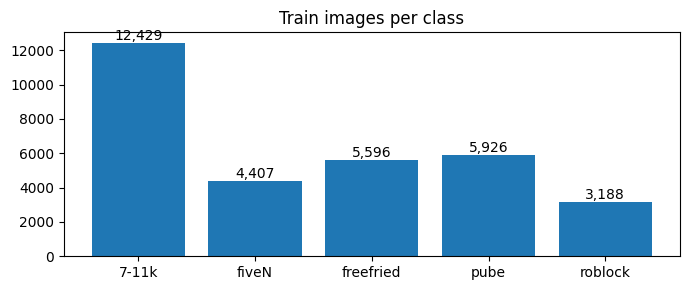

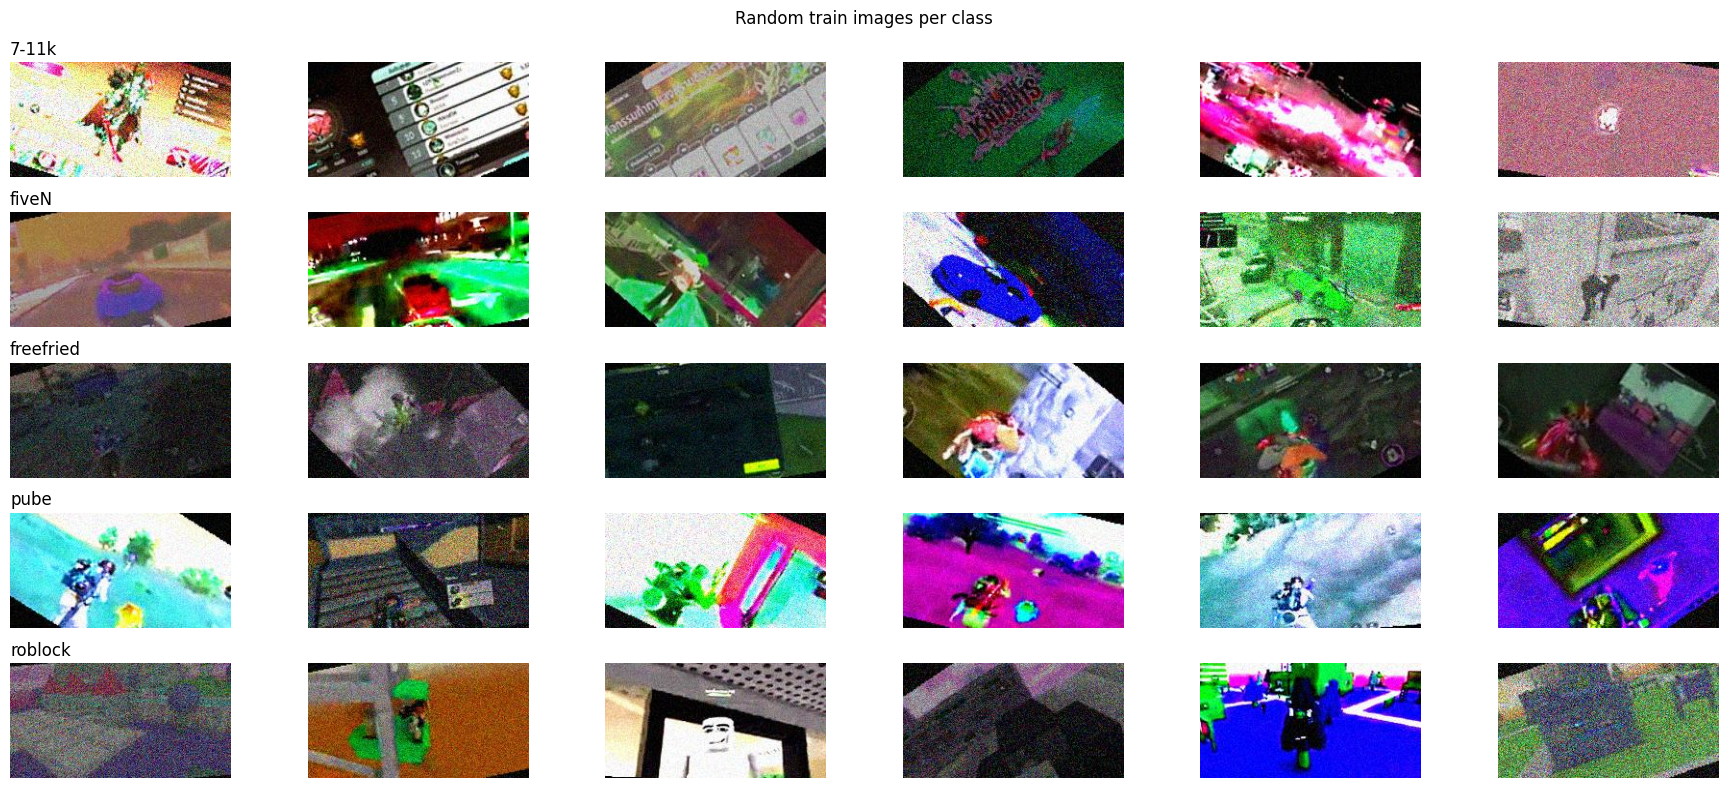

           brightness   contrast  saturation  dark_corners   hf_noise  rotated_%
7-11k      121.699997  58.160000        0.40          1.78  62.009998      74.79
fiveN      105.330002  54.880001        0.42          1.65  62.060001      72.79
freefried  110.949997  54.270000        0.43          1.64  63.529999      72.28
pube       109.019997  49.900002        0.57          1.57  61.810001      71.48
roblock    118.730003  56.990002        0.47          1.59  61.040001      71.80
TRAIN all  114.820000  55.340000        0.45          1.68  62.150002      73.14


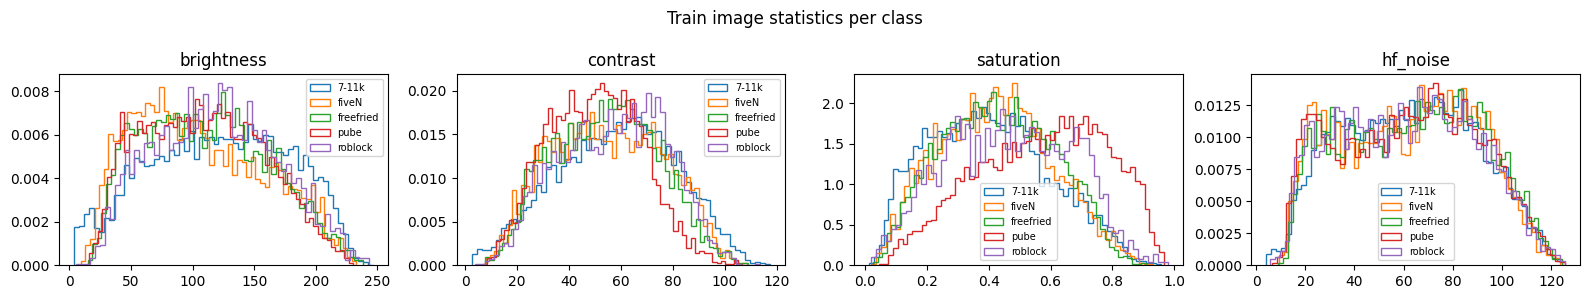


percentile ของภาพ train:
      brightness  contrast  hf_noise  saturation
0.01      15.889    12.471    13.866       0.081
0.05      34.747    21.686    19.784       0.136
0.50     113.535    55.644    63.227       0.440
0.95     201.774    89.727   105.126       0.786
0.99     220.477   100.618   115.130       0.883
ภาพขาวดำ 0.2% | ภาพหมุน (มุมดำ ≥ 2) 73.1%
ค่า augmentation จาก train (base): {'bri': (0.31, 1.78), 'con': (0.39, 1.61), 'sat': (0.31, 1.79), 'noise_s': 0.0923, 'gray': 0.002}
ค่า augmentation จาก train (strong): {'bri': (0.14, 1.94), 'con': (0.22, 1.81), 'sat': (0.19, 2.01), 'noise_s': 0.1057, 'gray': 0.004}
วัดมุมหมุนได้ 95.6% ของภาพ train | percentile (องศา): {0.01: 6.7, 0.05: 13.1, 0.5: 26.6, 0.95: 41.8, 0.99: 44.4}
มุมหมุนสูงสุดสำหรับ aug: base 42 | strong 44


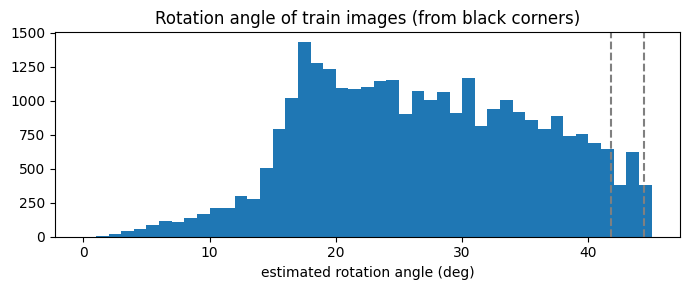

In [ ]:
# ===== 3. EDA: สัดส่วน class, ตัวอย่างภาพ, ลักษณะภาพ train ต่อ class (คำนวณบน GPU) · ใช้ภาพ train อย่างเดียว =====
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(CLASSES, vc.values)
for i, v in enumerate(vc.values): ax.text(i, v, f'{v:,}', ha='center', va='bottom')
ax.set_title('Train images per class'); plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
fig, axs = plt.subplots(5, 6, figsize=(18, 8))
for r, c in enumerate(CLASSES):
    for k, i in enumerate(rng.choice(np.where(y_all == r)[0], 6, replace=False)):
        axs[r, k].imshow(X_train[i]); axs[r, k].axis('off')
    axs[r, 0].set_title(c, loc='left')
plt.suptitle('Random train images per class'); plt.tight_layout(); plt.show()

@torch.no_grad()
def img_stats(X, bs=2048):
    w, out = torch.tensor([0.299, 0.587, 0.114], device=DEV).view(1, 3, 1, 1), []
    for s in range(0, len(X), bs):
        x = torch.from_numpy(X[s:s + bs]).to(DEV).permute(0, 3, 1, 2).float() / 255
        g = (x * w).sum(1); mx, mn = x.max(1).values, x.min(1).values
        corner = torch.stack([g[:, :8, :8], g[:, :8, -8:], g[:, -8:, :8], g[:, -8:, -8:]], 1).mean((2, 3))
        lap = (4 * g[:, 1:-1, 1:-1] - g[:, :-2, 1:-1] - g[:, 2:, 1:-1] - g[:, 1:-1, :-2] - g[:, 1:-1, 2:]).abs().mean((1, 2))
        out.append(torch.stack([g.mean((1, 2)) * 255, g.std((1, 2)) * 255, ((mx - mn) / (mx + 1e-6)).mean((1, 2)), (corner < 0.08).sum(1).float(), lap * 255], 1).cpu())
    return pd.DataFrame(torch.cat(out).numpy(), columns=['brightness', 'contrast', 'saturation', 'dark_corners', 'hf_noise'])
st_tr = img_stats(X_train)
summ = st_tr.groupby(train_df['class'].values).mean().reindex(CLASSES)
summ.loc['TRAIN all'] = st_tr.mean()
summ['rotated_%'] = [(st_tr['dark_corners'][y_all == k] >= 2).mean() * 100 for k in range(5)] + [(st_tr['dark_corners'] >= 2).mean() * 100]
print(summ.round(2).to_string())
fig, axs = plt.subplots(1, 4, figsize=(16, 3))
for ax, col in zip(axs, ['brightness', 'contrast', 'saturation', 'hf_noise']):
    for k, c in enumerate(CLASSES): ax.hist(st_tr[col][y_all == k], bins=60, density=True, histtype='step', label=c)
    ax.set_title(col); ax.legend(fontsize=7)
plt.suptitle('Train image statistics per class'); plt.tight_layout(); plt.show()

# ช่วงของ train ที่ใช้ตั้ง augmentation ใน section 5 · BASE = p5–p95 · STRONG = p1–p99
# หารด้วย median = ตัวคูณที่ทำให้ภาพกลางๆ ขยับไปถึงขอบช่วงนั้น
colored = st_tr['saturation'] >= 0.05                                  # ภาพขาวดำ (saturation ≈ 0) แยกนับเป็นโอกาสทำขาวดำ
Q = st_tr[['brightness', 'contrast', 'hf_noise']].quantile([0.01, 0.05, 0.5, 0.95, 0.99])
Q['saturation'] = st_tr['saturation'][colored].quantile([0.01, 0.05, 0.5, 0.95, 0.99])
print('\npercentile ของภาพ train:'); print(Q.round(3).to_string())
ratio = lambda col, lo, hi: (round(float(Q.loc[lo, col] / Q.loc[0.5, col]), 2), round(float(Q.loc[hi, col] / Q.loc[0.5, col]), 2))
noise_sd = lambda q: round(float(np.sqrt(max(Q.loc[q, 'hf_noise'] ** 2 - Q.loc[0.5, 'hf_noise'] ** 2, 0)) / (3.57 * 255)), 4)   # Gaussian σ: |Laplacian| เฉลี่ย ≈ 3.57σ
GRAY_RATE, ROT_RATE = float((~colored).mean()), float((st_tr['dark_corners'] >= 2).mean())
TRAIN_AUG = {'base':   dict(bri=ratio('brightness', .05, .95), con=ratio('contrast', .05, .95), sat=ratio('saturation', .05, .95), noise_s=noise_sd(.95), gray=round(GRAY_RATE, 3)),
             'strong': dict(bri=ratio('brightness', .01, .99), con=ratio('contrast', .01, .99), sat=ratio('saturation', .01, .99), noise_s=noise_sd(.99), gray=round(min(2 * GRAY_RATE, 0.5), 3))}
print(f'ภาพขาวดำ {GRAY_RATE*100:.1f}% | ภาพหมุน (มุมดำ ≥ 2) {ROT_RATE*100:.1f}%')
for k, v in TRAIN_AUG.items(): print(f'ค่า augmentation จาก train ({k}):', v)

# มุมหมุนของภาพ train: มุมภาพที่ถูกหมุนจะมีสามเหลี่ยมสีเดียว (สีดำที่ถูกทำสีเพี้ยน/กลับสี/noise ทีหลัง) ด้านตามขอบบน a และขอบข้าง b
# → มุม = atan(ด้านสั้น / ด้านยาว) (วัดได้ 0–45°) · ใช้ median ของมุมทั้ง 4 ที่วัดได้ในภาพ
import torch.nn.functional as F
@torch.no_grad()
def rot_angles(X, bs=1024, tol=25, row=3):
    out = []
    for s in range(0, len(X), bs):
        x = torch.from_numpy(X[s:s + bs]).to(DEV).permute(0, 3, 1, 2).float()
        x = F.avg_pool2d(F.pad(x, (2, 2, 2, 2), mode='replicate'), 5, 1)              # เบลอ 5×5 ลด noise
        ang = []
        for v in (x, x.flip(2), x.flip(3), x.flip(2).flip(3)):                       # มุมบนซ้าย / ล่างซ้าย / บนขวา / ล่างขวา
            uni = (v - v[:, :, :3, :3].mean((2, 3), keepdim=True)).abs().amax(1) < tol   # pixel สีเดียวกับมุม
            a, b = (~uni[:, row, :]).float().argmax(1).float(), (~uni[:, :, row]).float().argmax(1).float()
            ok = (a >= 6) & (b >= 6) & (a < 0.9 * v.shape[3]) & (b < 0.9 * v.shape[2])
            t = torch.rad2deg(torch.atan(torch.minimum(a, b) / torch.maximum(a, b).clamp(min=1)))
            ang.append(torch.where(ok, t, torch.full_like(t, float('nan'))))
        out.append(torch.stack(ang, 1).nanmedian(1).values.cpu())
    return torch.cat(out).numpy()
st_tr['rot_deg'] = rot_angles(X_train)
rq = st_tr['rot_deg'].dropna().quantile([0.01, 0.05, 0.5, 0.95, 0.99])
print(f'วัดมุมหมุนได้ {st_tr.rot_deg.notna().mean()*100:.1f}% ของภาพ train | percentile (องศา):', rq.round(1).to_dict())
TRAIN_AUG['base']['rot'], TRAIN_AUG['strong']['rot'] = round(float(rq[0.95])), round(float(rq[0.99]))
print('มุมหมุนสูงสุดสำหรับ aug: base', TRAIN_AUG['base']['rot'], '| strong', TRAIN_AUG['strong']['rot'])
plt.figure(figsize=(7, 3)); plt.hist(st_tr['rot_deg'].dropna(), bins=45, range=(0, 45))
for q in (0.95, 0.99): plt.axvline(rq[q], color='gray', ls='--')
plt.xlabel('estimated rotation angle (deg)'); plt.title('Rotation angle of train images (from black corners)'); plt.tight_layout(); plt.show()

**ผล:**
- จำนวนภาพ: 7-11k 12,429 · pube 5,926 · freefried 5,596 · fiveN 4,407 · roblock 3,188
- ภาพทุก class เสียแบบเดียวกัน: ≈73% ถูกหมุนจนมีมุมดำ ≥ 2 มุม (71.5–74.8% ต่อ class) สีเพี้ยน กลับสี มี noise
- สถิติของแต่ละ class ต่างกันน้อย (เด่นแค่ pube สีอิ่มสุด 0.57, 7-11k สว่างสุด 122) · histogram ของแต่ละ class ซ้อนกันเกือบหมด
- **ช่วงของ train (p5–p95):** brightness 35–202 · contrast 22–90 · saturation 0.14–0.79 (เฉพาะภาพมีสี) · ภาพขาวดำแค่ 0.2%
- **มุมหมุน:** มุมภาพที่ถูกหมุนเป็นสามเหลี่ยมสีเดียว (ดำที่ถูกทำสีเพี้ยน/กลับสีทีหลัง) วัดด้านบน/ด้านข้าง → มุม = atan(ด้านสั้น / ด้านยาว) · วัดได้ 95.6% ของภาพ · median 26.6° · p95 41.8° · p99 44.4° · ภาพส่วนใหญ่หมุน 15–45° มีน้อยที่หมุนต่ำกว่า 15°
- **ทำไมต้องดู:** เพื่อรู้ว่าต้องเลียนแบบความเสียหายแบบไหนใน augmentation และแรงแค่ไหน
- **ได้อะไร:** ช่วงสุ่มของ augmentation (section 5) ทั้งหมดได้จากตรงนี้: BASE ใช้ p5–p95, STRONG ใช้ p1–p99 (สีหารด้วย median เป็นตัวคูณ: brightness ×0.31–1.78, contrast ×0.39–1.61, saturation ×0.31–1.79) · noise σ 0.092 · ขาวดำ 0.2% · หมุนสูงสุด 42° / 44° · สีอย่างเดียวแยก class ไม่ได้ model ต้องดูเนื้อหาภาพ (UI / ฉากของเกม)
- **การใช้ test ใน section นี้:** ไม่ใช้ · ทุกสถิติคำนวณจากภาพ train อย่างเดียว

## 4. ที่เก็บผลใน Google Drive

In [ ]:
# ===== 4. บันทึก / โหลดผลจาก Drive (runtime หลุดได้ ผลไม่หาย) =====
# ต่อ 1 run (tag): result_{tag}.json = ประวัติ+คะแนน · valprobs_{tag}.npy · ckpt_{tag}.pt · testprobs_{tag}.npy
path_of = lambda kind, tag, ext: f'{RUN_DIR}/{kind}_{tag}.{ext}'
has_result = lambda tag: os.path.exists(path_of('result', tag, 'json'))
has_testprobs = lambda tag: os.path.exists(path_of('testprobs', tag, 'npy'))

def save_result(tag, res, valprobs, local_ckpt):
    shutil.copy(local_ckpt, path_of('ckpt', tag, 'pt'))
    if valprobs is not None: np.save(path_of('valprobs', tag, 'npy'), valprobs)
    json.dump(res, open(path_of('result', tag, 'json'), 'w'), default=float)

def load_result(tag):
    vp = path_of('valprobs', tag, 'npy')
    return json.load(open(path_of('result', tag, 'json'))), (np.load(vp) if os.path.exists(vp) else None)

def load_ckpt(model, tag):
    model.load_state_dict(torch.load(path_of('ckpt', tag, 'pt'), map_location=DEV)); return model

save_testprobs = lambda tag, p: np.save(path_of('testprobs', tag, 'npy'), p)
load_testprobs = lambda tag: np.load(path_of('testprobs', tag, 'npy'))
done = sorted(f[7:-5] for f in os.listdir(RUN_DIR) if f.startswith('result_'))
print(f'{RUN_DIR} | run ที่เสร็จแล้ว {len(done)}: {done}')

/content/drive/MyDrive/ml_task4_runs_v3 | run ที่เสร็จแล้ว 0: []


**ผล:** บอกว่าใน `ml_task4_runs_v3` มี run ไหนเสร็จแล้วบ้าง
- **ทำอะไร:** รวมฟังก์ชันบันทึก/โหลดผลไว้ที่เดียว: ประวัติการ train, prob ของ val, checkpoint, prob ของ test
- **ทำไม:** Colab หลุดได้ตลอด ผลที่บันทึกไว้แล้วจะถูกโหลดแทนการ train ซ้ำ กด Run all ใหม่ได้ทันที

## 5. เครื่องมือ train บน GPU

AUG_BASE  : {'sc': (0.85, 1.15), 'tr': 0.16, 'color_p': 0.8, 'hue': 0.15, 'inv': 0.1, 'blur_p': 0.2, 'blur_s': 1.5, 'noise_p': 0.3, 'erase_p': 0.0, 'bri': (0.31, 1.78), 'con': (0.39, 1.61), 'sat': (0.31, 1.79), 'noise_s': 0.0923, 'gray': 0.002, 'rot': 42}
AUG_STRONG: {'sc': (0.7, 1.35), 'tr': 0.3, 'color_p': 0.9, 'hue': 0.5, 'inv': 0.2, 'blur_p': 0.3, 'blur_s': 2.0, 'noise_p': 0.4, 'erase_p': 0.3, 'bri': (0.14, 1.94), 'con': (0.22, 1.81), 'sat': (0.19, 2.01), 'noise_s': 0.1057, 'gray': 0.004, 'rot': 44}


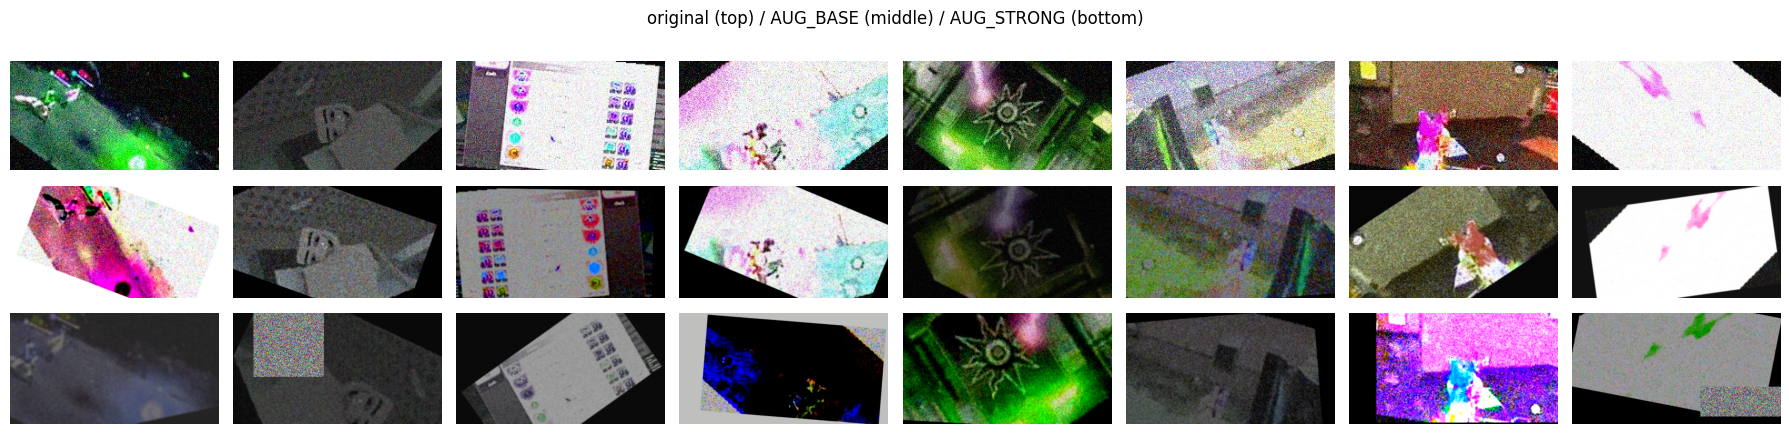

GPU augmentation 8,348 img/s | class weight {'7-11k': np.float32(1.0), 'fiveN': np.float32(1.68), 'freefried': np.float32(1.49), 'pube': np.float32(1.45), 'roblock': np.float32(1.97)}


In [ ]:
# ===== 5. ภาพทั้งหมดอยู่บน GPU · augmentation บน GPU ทีละ batch · train loop 2 ขั้น · ทำนาย + TTA =====
import torch.nn as nn, torch.nn.functional as F, timm.optim, timm.utils
from sklearn.metrics import f1_score, confusion_matrix, classification_report
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = torch.backends.cudnn.allow_tf32 = True
Xg_train, Xg_test, yg_all = torch.from_numpy(X_train).to(DEV), torch.from_numpy(X_test).to(DEV), torch.from_numpy(y_all).to(DEV)

# aug ที่เลียนแบบความเสียหายใน data · BASE = สูตรหลัก · STRONG = แรงขึ้น + random erasing
# สี (bri/con/sat), noise, โอกาสขาวดำ, มุมหมุน = จากช่วงของ train ใน section 3
# ที่เหลือ (ซูม, เลื่อน, hue, กลับสี, blur, โอกาสเกิด) = ค่าตั้งต้นทั่วไป
AUG_BASE = dict(sc=(0.85, 1.15), tr=0.16, color_p=0.8, hue=0.15, inv=0.1, blur_p=0.2, blur_s=1.5, noise_p=0.3, erase_p=0.0, **TRAIN_AUG['base'])
AUG_STRONG = dict(sc=(0.7, 1.35), tr=0.3, color_p=0.9, hue=0.5, inv=0.2, blur_p=0.3, blur_s=2.0, noise_p=0.4, erase_p=0.3, **TRAIN_AUG['strong'])
_YIQ = torch.tensor([[0.299, 0.587, 0.114], [0.596, -0.274, -0.322], [0.211, -0.523, 0.312]], device=DEV)
_IYIQ, _GRAY = torch.linalg.inv(_YIQ), torch.tensor([0.299, 0.587, 0.114], device=DEV).view(1, 3, 1, 1)

def gpu_augment(x, size, A):
    B, d = x.shape[0], x.device; H, W = size; r = H / W
    U = lambda lo, hi: torch.empty(B, device=d).uniform_(lo, hi)
    # หมุน + ซูม + เลื่อน + กลับซ้ายขวา + resize ในขั้นเดียว (นอกภาพ = ดำ เหมือนภาพที่ถูกหมุนใน data)
    ang, sc = U(-A['rot'], A['rot']) * math.pi / 180, U(*A['sc'])
    flip = torch.where(torch.rand(B, device=d) < 0.5, -1.0, 1.0); a, b = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([a * flip, -b * r, U(-A['tr'], A['tr'])], 1), torch.stack([b / r * flip, a, U(-A['tr'], A['tr'])], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, (B, 3, H, W), align_corners=False), mode='bilinear', padding_mode='zeros', align_corners=False)
    # สีเพี้ยน: brightness / contrast / saturation + hue (YIQ)
    sel = torch.rand(B, device=d) < A['color_p']; pick = lambda f, n: torch.where(sel, f, torch.full_like(f, n))
    bf, cf, sf, hue = pick(U(*A['bri']), 1.), pick(U(*A['con']), 1.), pick(U(*A['sat']), 1.), pick(U(-A['hue'], A['hue']), 0.) * 2 * math.pi
    x = x * bf.view(B, 1, 1, 1); m = x.mean((1, 2, 3), keepdim=True); x = (x - m) * cf.view(B, 1, 1, 1) + m
    R = torch.zeros(B, 3, 3, device=d); R[:, 0, 0] = 1
    R[:, 1, 1] = R[:, 2, 2] = torch.cos(hue) * sf; R[:, 1, 2] = -torch.sin(hue) * sf; R[:, 2, 1] = torch.sin(hue) * sf
    x = torch.einsum('bij,bjhw->bihw', _IYIQ @ R @ _YIQ, x).clamp_(0, 1)
    # กลับสี / ขาวดำ
    x = torch.where((torch.rand(B, device=d) < A['inv']).view(B, 1, 1, 1), 1 - x, x)
    x = torch.where((torch.rand(B, device=d) < A['gray']).view(B, 1, 1, 1), (x * _GRAY).sum(1, keepdim=True).expand_as(x), x)
    # Gaussian blur (separable, kernel 5)
    sig = torch.where(torch.rand(B, device=d) < A['blur_p'], U(0.1, A['blur_s']), torch.full((B,), 1e-3, device=d))
    t = torch.arange(-2, 3, device=d).float(); k = torch.exp(-t[None] ** 2 / (2 * sig[:, None] ** 2)); k = (k / k.sum(1, keepdim=True)).repeat_interleave(3, 0)
    y = F.conv2d(F.pad(x.reshape(1, B * 3, H, W), (2, 2, 0, 0), mode='reflect'), k.view(B * 3, 1, 1, 5), groups=B * 3)
    x = F.conv2d(F.pad(y, (0, 0, 2, 2), mode='reflect'), k.view(B * 3, 1, 5, 1), groups=B * 3).view(B, 3, H, W)
    # random erasing: สี่เหลี่ยม 5-25% ของภาพแทนด้วย noise
    if A['erase_p'] > 0:
        area, asp = U(0.05, 0.25), torch.exp(U(-1, 1))
        eh, ew = (area * asp).sqrt().clamp(max=1).view(B, 1, 1), (area / asp).sqrt().clamp(max=1).view(B, 1, 1)
        yy, xx = torch.linspace(0, 1, H, device=d).view(1, H, 1), torch.linspace(0, 1, W, device=d).view(1, 1, W)
        em = ((yy - U(0, 1).view(B, 1, 1)).abs() < eh / 2) & ((xx - U(0, 1).view(B, 1, 1)).abs() < ew / 2) & (torch.rand(B, device=d) < A['erase_p']).view(B, 1, 1)
        x = torch.where(em.unsqueeze(1), torch.rand_like(x), x)
    ns = torch.where(torch.rand(B, device=d) < A['noise_p'], U(0, A['noise_s']), torch.zeros(B, device=d))
    return (x + torch.randn_like(x) * ns.view(B, 1, 1, 1)).clamp_(0, 1)

print('AUG_BASE  :', AUG_BASE); print('AUG_STRONG:', AUG_STRONG)

def prep(xb, size, mean, std, train, aug=AUG_BASE):
    x = xb.permute(0, 3, 1, 2).float().div_(255)
    x = gpu_augment(x, size, aug) if train else F.interpolate(x, size=size, mode='bilinear', align_corners=False)
    return ((x - mean) / std).contiguous(memory_format=torch.channels_last)

cnt = np.bincount(y_all)
CW = torch.tensor((cnt.max() / cnt) ** 0.5, dtype=torch.float32, device=DEV)   # class weight (sqrt) สำหรับ macro F1

def build(cfg):
    kw = dict(pretrained=True, num_classes=len(CLASSES), drop_rate=0.2)
    if cfg.get('vit'): kw['img_size'] = cfg['size']
    m = timm.create_model(cfg['name'], **kw); dc = timm.data.resolve_model_data_config(m)
    return m.to(DEV).to(memory_format=torch.channels_last), torch.tensor(dc['mean'], device=DEV).view(1, 3, 1, 1), torch.tensor(dc['std'], device=DEV).view(1, 3, 1, 1)

@torch.no_grad()
def predict(model, Xg, idx, size, mean, std, bs=256, tta=False):
    model.eval(); out, idx = [], torch.as_tensor(idx, device=Xg.device)
    for s in range(0, len(idx), bs):
        x = prep(Xg[idx[s:s + bs]], size, mean, std, False)
        with torch.autocast('cuda', dtype=torch.bfloat16):
            p = model(x).float().softmax(1)
            if tta: p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2   # TTA = เฉลี่ยกับภาพกลับซ้ายขวา
        out.append(p)
    return torch.cat(out).cpu().numpy()

def run(cfg, tr_idx, va_idx, tag):
    """ขั้น 1 train แค่ head (backbone freeze) → ขั้น 2 fine-tune ทั้งตัว + cosine LR · CE + class weight + label smoothing
    ตัวเลือก: aug, mix (MixUp/CutMix), ema, layer_decay · va_idx=None = train ทั้งหมด ใช้ epoch สุดท้าย · มีผลใน Drive แล้ว = โหลดแทน"""
    if has_result(tag):
        res, vp = load_result(tag); print(f'[{tag}] โหลดผลเดิมจาก Drive'); return res, vp
    size, bs, ep_lp, ep_ft = cfg['size'], cfg.get('bs', 64), cfg.get('lp', 1), cfg.get('ep', 6)
    lr_scale, aug, mixp = math.sqrt(bs / 32), cfg.get('aug', AUG_BASE), cfg.get('mix', 0.0)
    torch.manual_seed(cfg.get('seed', 0)); np.random.seed(cfg.get('seed', 0))
    model, mean, std = build(cfg)
    tr_g = torch.as_tensor(tr_idx, device=DEV); steps = len(tr_g) // bs
    crit = nn.CrossEntropyLoss(weight=CW, label_smoothing=0.1)
    head = set(id(p) for p in model.get_classifier().parameters())
    hist, best, ema, local = [], dict(f1=-1.0, acc=float('nan'), ep=0, probs=None), None, f'/content/ckpt_{tag}.pt'
    torch.cuda.reset_peak_memory_stats()
    for phase, n_ep in [('LP', ep_lp), ('FT', ep_ft)]:
        for p in model.parameters(): p.requires_grad = (phase == 'FT') or (id(p) in head)
        if phase == 'FT' and cfg.get('layer_decay'):                     # LR ลดลงทีละ layer (layer ล่าง = LR น้อย)
            opt = timm.optim.create_optimizer_v2(model, opt='adamw', lr=cfg['lr'] * lr_scale, weight_decay=0.05, layer_decay=cfg['layer_decay'])
            for g in opt.param_groups: g['lr'] = g['lr'] * g.get('lr_scale', 1.0)
            params = [p for g in opt.param_groups for p in g['params']]
        else:
            params = [p for p in model.parameters() if p.requires_grad]
            opt = torch.optim.AdamW(params, lr=(cfg['lr_head'] if phase == 'LP' else cfg['lr']) * lr_scale, weight_decay=0.05, fused=True)
        if phase == 'FT' and cfg.get('ema'): ema = timm.utils.ModelEmaV3(model, decay=cfg['ema'], use_warmup=True)
        total, warm = n_ep * steps, (steps // 2 if phase == 'FT' else 0)
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / max(1, warm)) * 0.5 * (1 + np.cos(np.pi * min(1, s / total))))
        for ep in range(n_ep):
            model.train(); torch.cuda.synchronize(); t0 = time.time(); tl = torch.zeros((), device=DEV)
            perm = tr_g[torch.randperm(len(tr_g), device=DEV)]
            for s in range(steps):
                bi = perm[s * bs:(s + 1) * bs]
                x = prep(Xg_train[bi], size, mean, std, True, aug); y = yg_all[bi]; lam = 1.0
                if phase == 'FT' and mixp > 0 and np.random.rand() < mixp:
                    j = torch.randperm(len(bi), device=DEV)
                    if np.random.rand() < 0.5:                                # MixUp
                        lam = float(np.random.beta(0.4, 0.4)); x = lam * x + (1 - lam) * x[j]
                    else:                                                     # CutMix
                        Hh, Ww = x.shape[2:]; cr = math.sqrt(1 - np.random.beta(1, 1))
                        cy, cx = np.random.randint(Hh), np.random.randint(Ww); h2, w2 = int(Hh * cr) // 2, int(Ww * cr) // 2
                        y1, y2, x1, x2 = max(cy - h2, 0), min(cy + h2, Hh), max(cx - w2, 0), min(cx + w2, Ww)
                        x = x.clone(); x[:, :, y1:y2, x1:x2] = x[j][:, :, y1:y2, x1:x2]; lam = 1 - (y2 - y1) * (x2 - x1) / (Hh * Ww)
                with torch.autocast('cuda', dtype=torch.bfloat16):
                    out = model(x).float()
                    loss = crit(out, y) if lam == 1.0 else lam * crit(out, y) + (1 - lam) * crit(out, y[j])
                opt.zero_grad(set_to_none=True); loss.backward()
                nn.utils.clip_grad_norm_(params, 1.0); opt.step(); sched.step()
                if ema is not None: ema.update(model)
                tl += loss.detach()
            torch.cuda.synchronize(); t_tr = time.time() - t0
            evm = ema.module if ema is not None else model
            if va_idx is not None:
                pv = predict(evm, Xg_train, va_idx, size, mean, std); yv = y_all[va_idx]
                f1, acc = f1_score(yv, pv.argmax(1), average='macro'), (pv.argmax(1) == yv).mean()
                vl = float(F.nll_loss(torch.log(torch.tensor(pv) + 1e-9), torch.tensor(yv)))
            else:
                f1 = acc = vl = float('nan')
            hist.append(dict(phase=phase, ep=len(hist) + 1, train_loss=tl.item() / steps, val_loss=vl, val_f1=f1, val_acc=acc, sec=time.time() - t0))
            print(f'[{tag}] {phase} ep{len(hist)} | train_loss {tl.item()/steps:.4f} | val_loss {vl:.4f} | val macroF1 {f1:.4f} | acc {acc:.4f} | '
                  f'{time.time()-t0:.0f}s ({steps * bs / t_tr:.0f} img/s) | peak {torch.cuda.max_memory_allocated()/1e9:.1f} GB', flush=True)
            if va_idx is not None and f1 > best['f1']:
                best = dict(f1=f1, acc=acc, ep=len(hist), probs=pv); torch.save(evm.state_dict(), local)
    if va_idx is None:
        best = dict(f1=float('nan'), acc=float('nan'), ep=len(hist), probs=None); torch.save(evm.state_dict(), local)
    res = dict(tag=tag, name=cfg['name'], size=list(size), bs=bs, best_f1=best['f1'], best_acc=best['acc'], best_ep=best['ep'],
               sec_per_ep=float(np.mean([h['sec'] for h in hist if h['phase'] == 'FT'])), peak_gb=torch.cuda.max_memory_allocated() / 1e9, hist=hist)
    save_result(tag, res, best['probs'], local)
    del model, ema, opt; gc.collect(); torch.cuda.empty_cache()
    return res, best['probs']

# ตัวอย่าง aug: ภาพจริง (บน) / AUG_BASE (กลาง) / AUG_STRONG (ล่าง)
_m, _s, _i = torch.zeros(1, 3, 1, 1, device=DEV), torch.ones(1, 3, 1, 1, device=DEV), torch.arange(8, device=DEV)
fig, axs = plt.subplots(3, 8, figsize=(18, 4.5))
for k in range(8): axs[0, k].imshow(X_train[k])
for row, A in ((1, AUG_BASE), (2, AUG_STRONG)):
    a = prep(Xg_train[_i], (240, 448), _m, _s, True, A).permute(0, 2, 3, 1).float().cpu().numpy()
    for k in range(8): axs[row, k].imshow(a[k])
for ax in axs.flat: ax.axis('off')
plt.suptitle('original (top) / AUG_BASE (middle) / AUG_STRONG (bottom)'); plt.tight_layout(); plt.show()
torch.cuda.synchronize(); t0 = time.time()
for _ in range(20): prep(Xg_train[torch.randint(0, len(Xg_train), (128,), device=DEV)], (240, 448), _m, _s, True)
torch.cuda.synchronize(); print(f'GPU augmentation {20 * 128 / (time.time() - t0):,.0f} img/s | class weight', dict(zip(CLASSES, CW.cpu().numpy().round(2))))

**ผล:** แถวบน = ภาพจริง · แถวกลาง = AUG_BASE · แถวล่าง = AUG_STRONG · augmentation บน GPU ≈8,300 ภาพ/วินาที · class weight roblock 1.97 สูงสุด
- **ทำอะไร:** เก็บภาพทั้งหมดบน GPU แล้วทำ augmentation ทีละ batch บน GPU · train 2 ขั้น (train แค่ head 1 epoch → fine-tune ทั้งตัว + cosine LR) · ทำนายพร้อม TTA (เฉลี่ยกับภาพกลับซ้ายขวา)
- **ทำไม:** augmentation บน GPU เร็วกว่า CPU หลายเท่า ไม่เป็นคอขวด · ภาพที่ผ่าน augmentation หน้าตาเหมือนภาพจริงใน data (หมุน, สีเพี้ยน, กลับสี) model จึงเจอความเสียหายแบบเดียวกับที่ภาพใน data มี
- **ค่าของ augmentation มาจากไหน:** สี (brightness / contrast / saturation), ขนาด noise, โอกาสทำขาวดำ และมุมหมุน (BASE 42°, STRONG 44°) มาจากช่วงของภาพ train ใน section 3 · ค่าที่วัดจาก train ไม่ได้ (ซูม, เลื่อน, hue, กลับสี, blur, โอกาสเกิด) ใช้ค่าตั้งต้นทั่วไป

## 6. Validation ที่ไม่รั่วจาก train: group split

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

       split  near_dup_095  near_dup_090  median_cos  val_n  min_class_pct              val_class_pct
      random         1.220         6.165       0.772   6310         10.111 [39.4 14.  17.7 18.8 10.1]
  group k=50         0.028         0.667       0.731   7043          7.468 [29.9  7.5 25.8 27.4  9.4]
 group k=150         0.744         2.502       0.745   6314          9.471 [36.8 16.1 16.2 21.4  9.5]
 group k=400         0.805         2.918       0.750   5963          9.894 [41.4 13.2 17.  18.5  9.9]
group k=1000         1.547         3.512       0.757   6464          9.097 [37.6 14.6 17.8 21.   9.1]
เลือก group k=50: train 24,503 | val 7,043 | 152s


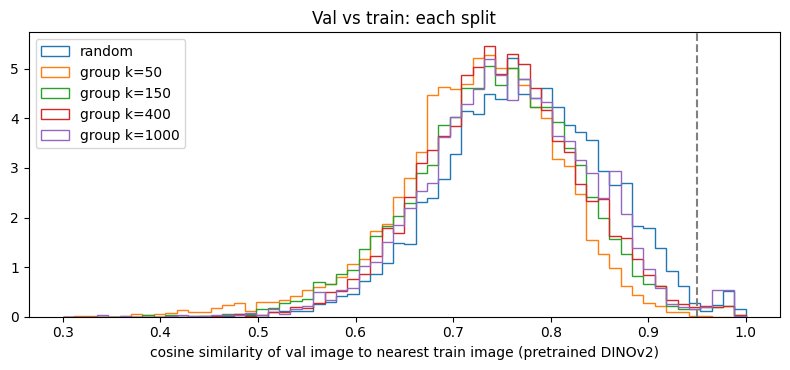

In [ ]:
# ===== 6. จัดภาพ train ที่คล้ายกัน (ฉาก/เฟรมเดียวกัน) เป็นกลุ่ม → กลุ่มเดียวกันอยู่ฝั่งเดียวกัน =====
# embedding จาก DINOv2 pretrain (ไม่ fine-tune) · ใช้ภาพ train อย่างเดียว
# เลือกจำนวนกลุ่ม k ที่ทำให้ภาพ val มีภาพเกือบซ้ำ (cosine > 0.95) อยู่ฝั่ง train น้อยที่สุด · ทุก class ใน val ต้อง ≥ 5%
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
t0 = time.time()
fe = timm.create_model('vit_base_patch14_reg4_dinov2.lvd142m', pretrained=True, num_classes=0, img_size=(224, 448)).to(DEV).eval()
dc = timm.data.resolve_model_data_config(fe)
fmu, fsd = torch.tensor(dc['mean'], device=DEV).view(1, 3, 1, 1), torch.tensor(dc['std'], device=DEV).view(1, 3, 1, 1)
@torch.no_grad()
def feats(Xg, bs=512):
    out = []
    for s in range(0, len(Xg), bs):
        with torch.autocast('cuda', dtype=torch.bfloat16): out.append(F.normalize(fe(prep(Xg[s:s + bs], (224, 448), fmu, fsd, False)).float(), dim=1))
    return torch.cat(out)
FT_tr = feats(Xg_train); del fe; gc.collect(); torch.cuda.empty_cache()

def nn_cos(Q, ref_idx, chunk=4096):                       # cosine กับภาพ train ที่ใกล้สุดใน ref_idx
    Rf = FT_tr[torch.as_tensor(ref_idx, device=DEV)]
    return torch.cat([(Q[s:s + chunk] @ Rf.T).max(1).values for s in range(0, len(Q), chunk)]).cpu().numpy()
def split_row(name, tr_i, va_i):
    c = nn_cos(FT_tr[torch.as_tensor(va_i, device=DEV)], tr_i); NN[name] = c
    pc = np.bincount(y_all[va_i], minlength=5) / len(va_i) * 100
    return dict(split=name, near_dup_095=(c > 0.95).mean() * 100, near_dup_090=(c > 0.90).mean() * 100, median_cos=np.median(c),
                val_n=len(va_i), min_class_pct=pc.min(), val_class_pct=str(pc.round(1)))

rtr, rva = train_test_split(np.arange(len(y_all)), test_size=0.2, stratify=y_all, random_state=42)
SPLITS, NN = {'random': (rtr, rva)}, {}
rows = [split_row('random', rtr, rva)]
Xf = FT_tr.cpu().numpy()
for k in [50, 150, 400, 1000]:
    grp = KMeans(n_clusters=k, n_init=1, random_state=0).fit_predict(Xf)
    tr_g, va_g = next(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(Xf, y_all, grp))
    SPLITS[f'group k={k}'] = (tr_g, va_g); rows.append(split_row(f'group k={k}', tr_g, va_g))
split_tab = pd.DataFrame(rows)
print(split_tab.round(3).to_string(index=False))
ok = split_tab[split_tab.split.str.startswith('group') & (split_tab.min_class_pct >= 5)]
BEST_SPLIT = ok.sort_values('near_dup_095').iloc[0]['split']
gtr, gva = SPLITS[BEST_SPLIT]
sp = f'{RUN_DIR}/splits.npz'                               # model grp_* ที่เก็บใน Drive train บน split นี้
if os.path.exists(sp):
    z = np.load(sp)
    if not np.array_equal(np.sort(z['gva']), np.sort(gva)):
        raise RuntimeError(f'{BEST_SPLIT} ไม่ตรงกับ splits.npz ใน Drive → model grp_* เดิม train บน split อื่น: เปลี่ยนชื่อโฟลเดอร์ ml_task4_runs แล้วรันใหม่')
    gtr, gva, rtr, rva = z['gtr'], z['gva'], z['rtr'], z['rva']; print('ใช้ split จาก Drive (ตรงกับที่คำนวณรอบนี้)')
else:
    np.savez(sp, gtr=gtr, gva=gva, rtr=rtr, rva=rva)
yg = y_all[gva]
print(f'เลือก {BEST_SPLIT}: train {len(gtr):,} | val {len(gva):,} | {time.time()-t0:.0f}s')
plt.figure(figsize=(8, 3.8))
for kname, c in NN.items(): plt.hist(c, bins=60, range=(0.3, 1), histtype='step', density=True, lw=2.5 if kname in ('random', BEST_SPLIT) else 1, label=kname)
plt.axvline(0.95, color='gray', ls='--'); plt.xlabel('cosine similarity of val image to nearest train image (pretrained DINOv2)')
plt.title('Val vs train: each split'); plt.legend(); plt.tight_layout(); plt.show()

**ผล:**

| วิธีแบ่ง val | ภาพ val ที่มีภาพเกือบซ้ำใน train (cosine > 0.95) | cosine > 0.90 | val |
|---|---|---|---|
| สุ่ม 20% | 1.22% | 6.17% | 6,310 |
| **group k = 50** | **0.03%** | **0.67%** | **7,043** |
| group k = 150 / 400 / 1000 | 0.74% / 0.81% / 1.55% | 2.50% / 2.92% / 3.51% | ≈6,000–6,500 |

- **ทำอะไร:** จัดภาพ train ที่หน้าตาคล้ายกัน (ฉาก/เฟรมเดียวกัน) เป็นกลุ่มด้วย embedding ของ DINOv2 แล้วให้ทั้งกลุ่มอยู่ฝั่งเดียวกัน (train หรือ val) · เลือก k ที่ภาพ val มีภาพเกือบซ้ำอยู่ฝั่ง train น้อยที่สุด และทุก class ใน val ≥ 5%
- **ทำไม:** ภาพในชุดนี้หลายภาพมาจากเฟรมใกล้กัน ถ้าแบ่งสุ่ม val จะมีภาพเกือบซ้ำกับ train คะแนนจึงสูงเกินจริง
- **ได้อะไร:** group k = 50 ลดภาพเกือบซ้ำจาก 1.22% เหลือ 0.03% (median cosine ถึงภาพ train ที่ใกล้สุด 0.731 vs สุ่ม 0.772 = val ห่างจาก train มากกว่า) → ใช้เป็น validation หลัก (train 24,503 / val 7,043) · สัดส่วน class ใน val เพี้ยนไปบ้าง (fiveN 7.5%) แต่ยังผ่านเกณฑ์ ≥ 5% · split ถูกบันทึกใน Drive (`splits.npz`) ทุกการรันซ้ำใช้ split เดียวกัน
- **การใช้ test ใน section นี้:** ไม่ใช้ · ใช้ภาพ train อย่างเดียว

## 7. val แบบสุ่ม vs group split

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

[rand_effv2] LP ep1 | train_loss 5.6905 | val_loss 3.0817 | val macroF1 0.3382 | acc 0.4081 | 30s (1074 img/s) | peak 10.2 GB
[rand_effv2] FT ep2 | train_loss 1.4811 | val_loss 0.2728 | val macroF1 0.9351 | acc 0.9412 | 64s (409 img/s) | peak 16.2 GB
[rand_effv2] FT ep3 | train_loss 0.6462 | val_loss 0.1909 | val macroF1 0.9596 | acc 0.9650 | 48s (553 img/s) | peak 16.2 GB
[rand_effv2] FT ep4 | train_loss 0.5675 | val_loss 0.1516 | val macroF1 0.9675 | acc 0.9726 | 48s (553 img/s) | peak 16.2 GB
[rand_effv2] FT ep5 | train_loss 0.5167 | val_loss 0.1425 | val macroF1 0.9817 | acc 0.9840 | 48s (552 img/s) | peak 16.2 GB
[rand_effv2] FT ep6 | train_loss 0.4917 | val_loss 0.1342 | val macroF1 0.9834 | acc 0.9856 | 48s (551 img/s) | peak 16.2 GB
[rand_effv2] FT ep7 | train_loss 0.4766 | val_loss 0.1338 | val macroF1 0.9847 | acc 0.9862 | 48s (552 img/s) | peak 16.2 GB
[grp_effv2] LP ep1 | train_loss 5.6745 | val_loss 3.8395 | val macroF1 0.2752 | acc 0.3386 | 22s (1386 img/s) | peak 7.7 GB


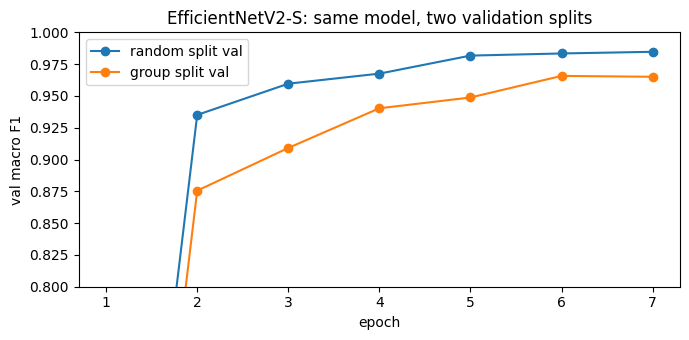

In [ ]:
# ===== 7. model เดียวกัน recipe เดียวกัน วัดด้วย val 2 แบบ → val แบบสุ่มให้คะแนนเกินจริงแค่ไหน =====
EFF = dict(name='tf_efficientnetv2_s.in21k_ft_in1k', size=(240, 448), lr=3e-4, lr_head=1e-3, bs=64)
R, P = {}, {}
R['rand_effv2'], P['rand_effv2'] = run(EFF, rtr, rva, 'rand_effv2')
R['grp_effv2'], P['grp_effv2'] = run(EFF, gtr, gva, 'grp_effv2')
for t, va in [('rand_effv2', rva), ('grp_effv2', gva)]:
    print(f'{t:11s} val macro F1 {f1_score(y_all[va], P[t].argmax(1), average="macro"):.4f} | acc {(P[t].argmax(1) == y_all[va]).mean():.4f} | epoch ที่ดีสุด {R[t]["best_ep"]}')
plt.figure(figsize=(7, 3.5))
for t, lab in [('rand_effv2', 'random split val'), ('grp_effv2', 'group split val')]:
    h = R[t]['hist']; plt.plot([x['ep'] for x in h], [x['val_f1'] for x in h], 'o-', label=lab)
plt.ylim(0.8, 1); plt.xlabel('epoch'); plt.ylabel('val macro F1'); plt.title('EfficientNetV2-S: same model, two validation splits'); plt.legend(); plt.tight_layout(); plt.show()

**ผล:** EfficientNetV2-S ตัวเดียวกัน: val แบบสุ่ม **0.9847** vs group-val **0.9657** · กราฟ: เส้น val แบบสุ่มอยู่สูงกว่าทุก epoch
- **ทำอะไร:** train model เดียวกัน recipe เดียวกันบน 2 split แล้วเทียบคะแนน
- **ทำไม:** เพื่อดูว่า val แบบสุ่มหลอกเราแค่ไหน
- **ได้อะไร:** val แบบสุ่มให้คะแนนสูงเกินจริงราว 0.02 · จากนี้ทุกการเทียบ model และการเลือก ensemble ใช้ group-val เท่านั้น · group-val ใช้เทียบว่าวิธีไหนดีกว่า ไม่ใช้เป็นคะแนนคาดการณ์

## 8. เทียบ 7 model บน group split

[grp_effv2_strong12] LP ep1 | train_loss 5.8908 | val_loss 3.9081 | val macroF1 0.2657 | acc 0.3315 | 21s (1375 img/s) | peak 7.5 GB
[grp_effv2_strong12] FT ep2 | train_loss 1.8273 | val_loss 0.5964 | val macroF1 0.7551 | acc 0.7853 | 47s (547 img/s) | peak 16.2 GB
[grp_effv2_strong12] FT ep3 | train_loss 0.9767 | val_loss 0.3531 | val macroF1 0.8898 | acc 0.9118 | 47s (547 img/s) | peak 16.2 GB
[grp_effv2_strong12] FT ep4 | train_loss 0.8659 | val_loss 0.3348 | val macroF1 0.8964 | acc 0.9179 | 47s (548 img/s) | peak 16.2 GB
[grp_effv2_strong12] FT ep5 | train_loss 0.8676 | val_loss 0.2799 | val macroF1 0.9272 | acc 0.9391 | 47s (547 img/s) | peak 16.2 GB
[grp_effv2_strong12] FT ep6 | train_loss 0.8204 | val_loss 0.2720 | val macroF1 0.9326 | acc 0.9469 | 47s (546 img/s) | peak 16.2 GB
[grp_effv2_strong12] FT ep7 | train_loss 0.7707 | val_loss 0.2543 | val macroF1 0.9493 | acc 0.9568 | 47s (548 img/s) | peak 16.2 GB
[grp_effv2_strong12] FT ep8 | train_loss 0.7535 | val_loss 0.2701 | v

model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

[grp_convnext] LP ep1 | train_loss 1.0068 | val_loss 0.7431 | val macroF1 0.7163 | acc 0.7514 | 43s (922 img/s) | peak 10.1 GB
[grp_convnext] FT ep2 | train_loss 0.7111 | val_loss 0.2909 | val macroF1 0.9193 | acc 0.9289 | 85s (306 img/s) | peak 19.3 GB
[grp_convnext] FT ep3 | train_loss 0.5335 | val_loss 0.1930 | val macroF1 0.9497 | acc 0.9601 | 73s (365 img/s) | peak 19.3 GB
[grp_convnext] FT ep4 | train_loss 0.4872 | val_loss 0.1717 | val macroF1 0.9608 | acc 0.9689 | 73s (365 img/s) | peak 19.3 GB
[grp_convnext] FT ep5 | train_loss 0.4659 | val_loss 0.1600 | val macroF1 0.9672 | acc 0.9754 | 73s (365 img/s) | peak 19.3 GB
[grp_convnext] FT ep6 | train_loss 0.4526 | val_loss 0.1421 | val macroF1 0.9765 | acc 0.9814 | 73s (364 img/s) | peak 19.3 GB
[grp_convnext] FT ep7 | train_loss 0.4477 | val_loss 0.1420 | val macroF1 0.9782 | acc 0.9825 | 73s (363 img/s) | peak 19.3 GB
[grp_dino] LP ep1 | train_loss 1.0105 | val_loss 0.7986 | val macroF1 0.7082 | acc 0.7449 | 30s (1020 img/s) | 

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

[grp_convnext_dino3] LP ep1 | train_loss 1.0522 | val_loss 0.7906 | val macroF1 0.6787 | acc 0.7105 | 30s (1021 img/s) | peak 10.1 GB
[grp_convnext_dino3] FT ep2 | train_loss 0.8669 | val_loss 0.5072 | val macroF1 0.8250 | acc 0.8583 | 73s (363 img/s) | peak 19.3 GB
[grp_convnext_dino3] FT ep3 | train_loss 0.7240 | val_loss 0.3439 | val macroF1 0.8747 | acc 0.8986 | 73s (363 img/s) | peak 19.3 GB
[grp_convnext_dino3] FT ep4 | train_loss 0.6182 | val_loss 0.2537 | val macroF1 0.9202 | acc 0.9338 | 73s (363 img/s) | peak 19.3 GB
[grp_convnext_dino3] FT ep5 | train_loss 0.5505 | val_loss 0.2420 | val macroF1 0.9425 | acc 0.9438 | 73s (363 img/s) | peak 19.3 GB
[grp_convnext_dino3] FT ep6 | train_loss 0.5004 | val_loss 0.1807 | val macroF1 0.9559 | acc 0.9652 | 73s (363 img/s) | peak 19.3 GB
[grp_convnext_dino3] FT ep7 | train_loss 0.4788 | val_loss 0.1694 | val macroF1 0.9635 | acc 0.9695 | 73s (363 img/s) | peak 19.3 GB


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.21GB            

model.safetensors: downloading bytes:           |  0.00B            

[grp_dino3L] LP ep1 | train_loss 1.0413 | val_loss 0.7965 | val macroF1 0.7319 | acc 0.7647 | 95s (324 img/s) | peak 9.8 GB
[grp_dino3L] FT ep2 | train_loss 0.7090 | val_loss 0.5453 | val macroF1 0.8453 | acc 0.8680 | 249s (106 img/s) | peak 26.2 GB
[grp_dino3L] FT ep3 | train_loss 0.5237 | val_loss 0.2728 | val macroF1 0.9411 | acc 0.9500 | 249s (106 img/s) | peak 26.2 GB
[grp_dino3L] FT ep4 | train_loss 0.4853 | val_loss 0.1680 | val macroF1 0.9582 | acc 0.9651 | 250s (106 img/s) | peak 26.2 GB
[grp_dino3L] FT ep5 | train_loss 0.4681 | val_loss 0.1514 | val macroF1 0.9638 | acc 0.9705 | 249s (106 img/s) | peak 26.2 GB
[grp_dino3L] FT ep6 | train_loss 0.4609 | val_loss 0.1534 | val macroF1 0.9666 | acc 0.9723 | 249s (106 img/s) | peak 26.2 GB
[grp_dino3L] FT ep7 | train_loss 0.4578 | val_loss 0.1566 | val macroF1 0.9671 | acc 0.9725 | 249s (106 img/s) | peak 26.2 GB
               tag  macro_F1    acc  best_ep  sec_per_ep  peak_gb  7-11k  fiveN  freefried   pube  roblock
         grp_

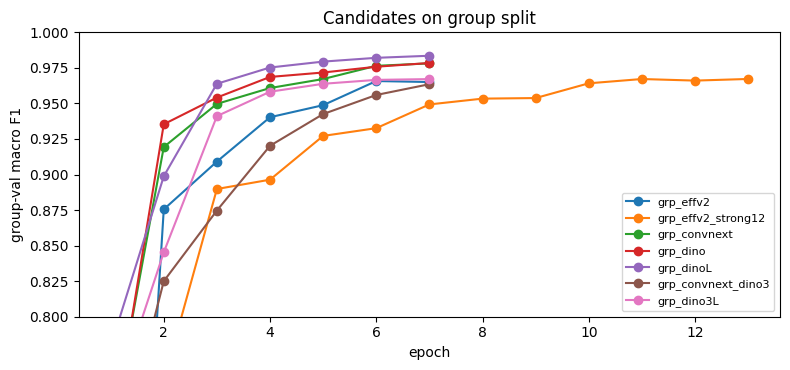

In [ ]:
# ===== 8. CNN 4 แบบ + ViT 3 แบบ บน group split (recipe เดียวกัน: head 1 epoch + fine-tune) =====
DINO = dict(name='vit_base_patch14_reg4_dinov2.lvd142m', size=(224, 448), lr=2e-5, lr_head=1e-3, vit=True, bs=48)
CAND = {'grp_effv2': EFF,                                                                     # EfficientNetV2-S
        'grp_effv2_strong12': dict(EFF, aug=AUG_STRONG, mix=0.5, ep=12),                       # + aug แรง + MixUp/CutMix, 12 epoch
        'grp_convnext': dict(name='convnext_small.fb_in22k_ft_in1k', size=(240, 448), lr=1e-4, lr_head=1e-3, bs=64),
        'grp_dino': DINO,                                                                     # DINOv2-B
        'grp_dinoL': dict(DINO, name='vit_large_patch14_reg4_dinov2.lvd142m', lr=5e-5, layer_decay=0.8, ema=0.999, bs=32),   # DINOv2-L + layer decay + EMA
        'grp_convnext_dino3': dict(name='convnext_small.dinov3_lvd1689m', size=(240, 448), lr=1e-4, lr_head=1e-3, bs=64),       # ConvNeXt-S distill จาก DINOv3
        'grp_dino3L': dict(DINO, name='vit_large_patch16_dinov3.lvd1689m', lr=5e-5, layer_decay=0.8, ema=0.999, bs=32)}       # DINOv3 ViT-L/16 + layer decay + EMA
for t, c in list(CAND.items()):
    if t in P: continue
    try:
        R[t], P[t] = run(c, gtr, gva, t)
    except Exception as e:                                     # เช่น โหลด weights ไม่ได้ → ข้ามตัวนี้ ไม่ให้ทั้ง notebook หยุด
        print(f'[{t}] ข้าม: {type(e).__name__}: {str(e)[:200]}'); CAND.pop(t); gc.collect(); torch.cuda.empty_cache()
board = pd.DataFrame([dict(tag=t, macro_F1=f1_score(yg, P[t].argmax(1), average='macro'), acc=(P[t].argmax(1) == yg).mean(), best_ep=R[t]['best_ep'],
                           sec_per_ep=R[t]['sec_per_ep'], peak_gb=R[t]['peak_gb'], **dict(zip(CLASSES, f1_score(yg, P[t].argmax(1), average=None)))) for t in CAND])
print(board.sort_values('macro_F1', ascending=False).round(4).to_string(index=False))
plt.figure(figsize=(8, 3.8))
for t in CAND:
    h = R[t]['hist']; plt.plot([x['ep'] for x in h], [x['val_f1'] for x in h], 'o-', label=t)
plt.ylim(0.8, 1); plt.xlabel('epoch'); plt.ylabel('group-val macro F1'); plt.title('Candidates on group split'); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**ผล (group-val macro F1):**

| model | macro F1 | วินาที/epoch |
|---|---|---|
| DINOv2-L | **0.9835** | 242 |
| DINOv2-B | 0.9784 | 78 |
| ConvNeXt-S | 0.9782 | 75 |
| EfficientNetV2-S + aug แรง 12 epoch | 0.9672 | 47 |
| DINOv3 ViT-L | 0.9671 | 249 |
| EfficientNetV2-S | 0.9657 | 47 |
| ConvNeXt-S (DINOv3) | 0.9635 | 73 |

- **ทำอะไร:** train 7 model บน group split ด้วย recipe เดียวกัน (head 1 epoch → fine-tune) แล้วเทียบ macro F1
- **ทำไม:** หา backbone ที่ทนภาพเสียได้ดีที่สุด และหาตัวที่ต่างกันพอจะเอามา ensemble
- **ได้อะไร:** DINOv2-L ดีที่สุด · DINOv3 ทั้ง 2 ตัวแพ้ DINOv2 รุ่นเดียวกัน · roblock เป็น class ที่ยากสุดของทุก model (F1 0.936–0.976) · กราฟ: ทุก model ได้คะแนนดีสุดที่ epoch สุดท้ายหรือใกล้สุดท้าย ไม่มีสัญญาณ overfit

## 9. เลือก ensemble

10 อันดับแรก:
  0.9865  ('grp_effv2_strong12', 'grp_convnext', 'grp_dino', 'grp_dinoL')
  0.9862  ('grp_effv2_strong12', 'grp_convnext', 'grp_dinoL')
  0.9861  ('grp_effv2_strong12', 'grp_convnext', 'grp_dinoL', 'grp_dino3L')
  0.9861  ('grp_effv2_strong12', 'grp_dino', 'grp_dinoL', 'grp_dino3L')
  0.9860  ('grp_effv2_strong12', 'grp_convnext', 'grp_dino', 'grp_dinoL', 'grp_dino3L')
  0.9858  ('grp_effv2_strong12', 'grp_convnext', 'grp_dino', 'grp_dinoL', 'grp_convnext_dino3', 'grp_dino3L')
  0.9856  ('grp_effv2', 'grp_effv2_strong12', 'grp_convnext', 'grp_dino', 'grp_dinoL', 'grp_dino3L')
  0.9855  ('grp_effv2', 'grp_effv2_strong12', 'grp_convnext', 'grp_dino', 'grp_dinoL')
  0.9855  ('grp_effv2_strong12', 'grp_convnext', 'grp_dinoL', 'grp_convnext_dino3', 'grp_dino3L')
  0.9854  ('grp_effv2', 'grp_effv2_strong12', 'grp_dino', 'grp_dinoL')

เลือก ['grp_effv2_strong12', 'grp_convnext', 'grp_dino', 'grp_dinoL'] → group-val macro F1 0.9865 (ตัวเดียวที่ดีสุด 0.9835)

              precisi

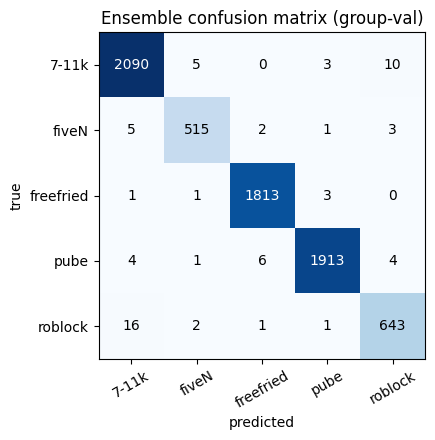

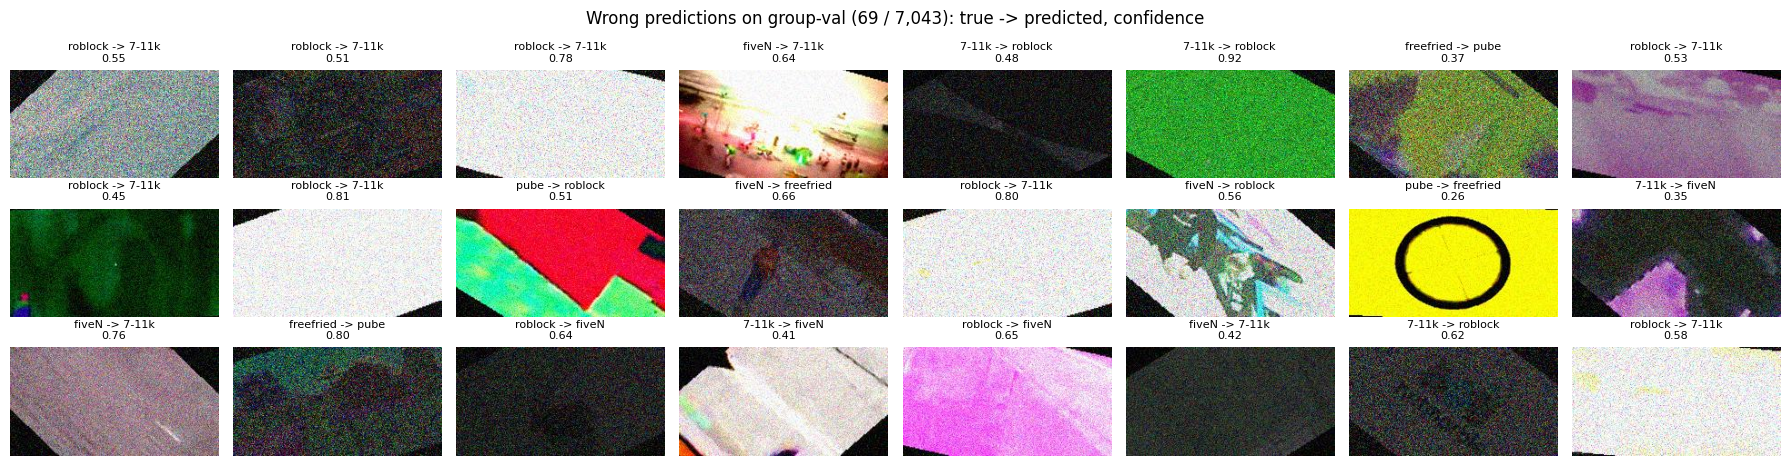

In [ ]:
# ===== 9. ลองเฉลี่ย prob ทุก combination ของ model ใน section 8 บน group-val → เลือกชุดที่ macro F1 สูงสุด (เสมอกันเลือกชุดเล็กกว่า) =====
combos = []
for n in range(1, len(CAND) + 1):
    for cmb in itertools.combinations(CAND, n):
        combos.append((f1_score(yg, np.mean([P[t] for t in cmb], 0).argmax(1), average='macro'), n, cmb))
combos.sort(key=lambda x: (-round(x[0], 4), x[1]))
print('10 อันดับแรก:'); [print(f'  {f:.4f}  {cmb}') for f, n, cmb in combos[:10]]
ENS = list(combos[0][2]); json.dump(ENS, open(f'{RUN_DIR}/ensemble.json', 'w'))
pe = np.mean([P[t] for t in ENS], 0); pred = pe.argmax(1)
print(f'\nเลือก {ENS} → group-val macro F1 {combos[0][0]:.4f} (ตัวเดียวที่ดีสุด {board.macro_F1.max():.4f})\n')
print(classification_report(yg, pred, target_names=CLASSES, digits=4))
cm = confusion_matrix(yg, pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5)); ax.imshow(cm, cmap='Blues')
for i in range(5):
    for j in range(5): ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks(range(5), CLASSES, rotation=30); ax.set_yticks(range(5), CLASSES); ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title('Ensemble confusion matrix (group-val)'); plt.tight_layout(); plt.show()
wrong = np.where(pred != yg)[0]; show = np.random.default_rng(0).choice(wrong, min(24, len(wrong)), replace=False)
fig, axs = plt.subplots(3, 8, figsize=(18, 4.8))
for ax, i in zip(axs.flat, show):
    ax.imshow(X_train[gva[i]]); ax.set_title(f'{CLASSES[yg[i]]} -> {CLASSES[pred[i]]}\n{pe[i].max():.2f}', fontsize=8); ax.axis('off')
for ax in axs.flat[len(show):]: ax.axis('off')
plt.suptitle(f'Wrong predictions on group-val ({len(wrong)} / {len(yg):,}): true -> predicted, confidence'); plt.tight_layout(); plt.show()

**ผล:** ชุดที่ดีสุด = EfficientNetV2-S (aug แรง) + ConvNeXt-S + DINOv2-B + DINOv2-L → group-val macro F1 **0.9865** (ตัวเดียวที่ดีสุด 0.9835) · accuracy 0.9902 · ผิด 69 จาก 7,043 ภาพ

| class | precision | recall | F1 |
|---|---|---|---|
| 7-11k | 0.988 | 0.992 | 0.990 |
| fiveN | 0.983 | 0.979 | 0.981 |
| freefried | 0.995 | 0.997 | 0.996 |
| pube | 0.996 | 0.992 | 0.994 |
| roblock | 0.974 | 0.970 | 0.972 |

- **ทำอะไร:** เฉลี่ย prob ของทุก combination ของ 7 model บน group-val แล้วเลือกชุดที่ macro F1 สูงสุด (เสมอกันเลือกชุดเล็กกว่า)
- **ทำไม:** model ต่างสถาปัตยกรรมผิดคนละภาพ เฉลี่ยกันแล้วผิดน้อยลง
- **ได้อะไร:** ensemble ดีกว่าตัวเดียว +0.003 · DINOv3 ไม่ได้ถูกเลือก · roblock ยังเป็นจุดอ่อน (F1 0.972) · confusion matrix: ที่ผิดมากสุดคือ roblock ↔ 7-11k (roblock ถูกทายเป็น 7-11k 16 ภาพ, 7-11k เป็น roblock 10 ภาพ)

## 10. ตัวส่ง: train บน train ทั้งหมด → ทำนาย test

In [ ]:
# ===== 10. train ชุดที่เลือกบน train ทั้งหมด (31,546 ภาพ, สูตร + epoch เดิม, ไม่มี val) → TTA → เฉลี่ย prob → task4_pred.csv =====
# test ใช้แค่ทำนาย · คำตอบเรียงตาม id ใน test.csv (จับคู่ภาพผ่าน file_name แล้วตั้งแต่ section 2)
all_idx, TP = np.arange(len(y_all)), {}
for g in ENS:
    t, c = g.replace('grp_', 'full_'), CAND[g]
    if not has_testprobs(t):
        run(c, all_idx, None, t)
        m, mu, sd = build(c); load_ckpt(m, t)
        save_testprobs(t, predict(m, Xg_test, np.arange(len(X_test)), c['size'], mu, sd, tta=True)); del m; gc.collect(); torch.cuda.empty_cache()
    TP[t] = load_testprobs(t)
pf = np.mean([TP[t] for t in TP], 0)
sub = pd.DataFrame({'id': test_ids, 'task4': pf.argmax(1).astype(int)})
assert len(sub) == 25889 and sub['task4'].between(0, 4).all() and (sub['id'] == [f'ANS{i+1:05d}' for i in range(len(sub))]).all()
sub.to_csv('/content/task4_pred.csv', index=False); sub.to_csv(f'{RUN_DIR}/task4_pred.csv', index=False)
pct = lambda p: (np.bincount(p.argmax(1), minlength=5) / len(p) * 100).round(1)
print('สัดส่วนคำตอบ % (' + ' / '.join(CLASSES) + ') และ % ภาพที่ไม่มั่นใจ (maxprob < 0.8):')
for t in TP: print(f'  {t:20s} {pct(TP[t])} | {(TP[t].max(1) < 0.8).mean()*100:4.1f}%')
print(f'  {"ensemble":20s} {pct(pf)} | {(pf.max(1) < 0.8).mean()*100:4.1f}%   (train {(cnt / cnt.sum() * 100).round(1)})')
ks = list(TP); print('model ทายตรงกันบน test:', {f'{a[5:]}~{b[5:]}': round(float((TP[a].argmax(1) == TP[b].argmax(1)).mean() * 100), 1) for i, a in enumerate(ks) for b in ks[i + 1:]})
print(sub.head(3).to_string(index=False), '\n... rows', len(sub), '| saved task4_pred.csv ใน /content และ', RUN_DIR)

[full_effv2_strong12] LP ep1 | train_loss 5.6931 | val_loss nan | val macroF1 nan | acc nan | 23s (1366 img/s) | peak 5.6 GB
[full_effv2_strong12] FT ep2 | train_loss 1.6873 | val_loss nan | val macroF1 nan | acc nan | 58s (547 img/s) | peak 16.2 GB
[full_effv2_strong12] FT ep3 | train_loss 0.9508 | val_loss nan | val macroF1 nan | acc nan | 58s (548 img/s) | peak 16.2 GB
[full_effv2_strong12] FT ep4 | train_loss 0.8746 | val_loss nan | val macroF1 nan | acc nan | 57s (548 img/s) | peak 16.2 GB
[full_effv2_strong12] FT ep5 | train_loss 0.8357 | val_loss nan | val macroF1 nan | acc nan | 58s (547 img/s) | peak 16.2 GB
[full_effv2_strong12] FT ep6 | train_loss 0.7794 | val_loss nan | val macroF1 nan | acc nan | 58s (547 img/s) | peak 16.2 GB
[full_effv2_strong12] FT ep7 | train_loss 0.7728 | val_loss nan | val macroF1 nan | acc nan | 58s (548 img/s) | peak 16.2 GB
[full_effv2_strong12] FT ep8 | train_loss 0.7457 | val_loss nan | val macroF1 nan | acc nan | 58s (547 img/s) | peak 16.2 GB


**ผล:** train 4 model ของ ensemble บน train ทั้งหมด (31,546 ภาพ) → ทำนาย test 25,889 ภาพ → `task4_pred.csv`
- สัดส่วนคำตอบของ ensemble: 7-11k 15.4% · fiveN 27.4% · freefried 14.9% · pube 24.8% · roblock 17.5% (train: 39.4 / 14.0 / 17.7 / 18.8 / 10.1)
- ภาพที่ไม่มั่นใจ (maxprob < 0.8): DINOv2-L 8.9% · DINOv2-B 20.2% · ConvNeXt-S 20.1% · EfficientNetV2-S 42.8% · ensemble 29.7%
- model แต่ละคู่ทายตรงกัน 85–91% (DINOv2-B กับ DINOv2-L ตรงกันมากสุด 90.7%)
- **ทำอะไร:** ใช้ recipe และจำนวน epoch เดิม แต่ train บนภาพ train ทั้งหมด (ไม่มี val) แล้วทำนาย test พร้อม TTA กลับซ้ายขวา เฉลี่ย prob ของ 4 model
- **ทำไม:** ใช้ข้อมูลทั้งหมดให้ model เห็นฉากมากที่สุด · เลือกชุด model และ epoch จาก group-val ไปแล้ว ไม่ต้องใช้ val อีก
- **ได้อะไร:** ไฟล์ส่ง (เรียงตาม id ใน test.csv) · สัดส่วนคำตอบบน test ต่างจาก train มาก และ model ทายตรงกันน้อยกว่าบน val → ภาพ test น่าจะยากหรือต่างจาก train มากกว่า val
- **การใช้ test ใน section นี้:** ใช้แค่ทำนายคำตอบ